In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("C:/Users/shiva/Downloads/Diwali_Sales_Data.csv", encoding="cp1252")

In [6]:
df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [7]:
# Total rows and columns
print(df.shape)

(11251, 15)


In [32]:
# Column names
print(df.columns)

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='str')


In [33]:
# Information about dataset
df.info()

<class 'pandas.DataFrame'>
Index: 11231 entries, 0 to 11250
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11231 non-null  int64  
 1   Cust_name         11231 non-null  str    
 2   Product_ID        11231 non-null  str    
 3   Gender            11231 non-null  str    
 4   Age Group         11231 non-null  str    
 5   Age               11231 non-null  int64  
 6   Marital_Status    11231 non-null  int64  
 7   State             11231 non-null  str    
 8   Zone              11231 non-null  str    
 9   Occupation        11231 non-null  str    
 10  Product_Category  11231 non-null  str    
 11  Orders            11231 non-null  int64  
 12  Amount            11231 non-null  float64
dtypes: float64(1), int64(4), str(8)
memory usage: 1.9 MB


In [34]:
# Statistical summary
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123100e+04,11231.000000,11231.000000,11231.000000,11231.000000
mean,1.003004e+06,35.411985,0.419998,2.489093,9454.084982
std,1.716055e+03,12.756116,0.493580,1.114880,5221.728776
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003065e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004428e+06,43.000000,1.000000,3.000000,12677.500000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


In [35]:
#  Checking Missing values
df.isnull().sum()

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

In [37]:
# Data Cleaning
# Empty columns remove 
df.drop(columns=["Status", "unnamed1"], inplace=True)

KeyError: "['Status', 'unnamed1'] not found in axis"

In [38]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='str')

In [39]:
# Duplicate rows check and remove 
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [40]:
df.drop_duplicates(inplace=True)

In [41]:
# Amount missing wali rows remove karo
df.dropna(subset=["Amount"], inplace=True)

In [42]:
# Updated dataset check 
print(df.shape)

(11231, 13)


In [43]:
print(df.isnull().sum())

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64


In [44]:
# Data types check 
print(df.dtypes)

User_ID               int64
Cust_name               str
Product_ID              str
Gender                  str
Age Group               str
Age                   int64
Marital_Status        int64
State                   str
Zone                    str
Occupation              str
Product_Category        str
Orders                int64
Amount              float64
dtype: object


In [45]:
#  Exploratory Data Analysis (EDA)

Gender
F    74307682.43
M    31871146.00
Name: Amount, dtype: float64


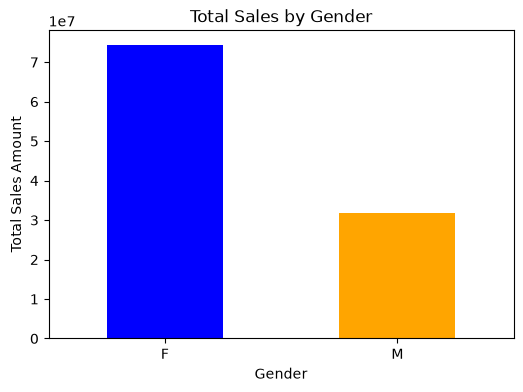

In [46]:
# Gender-wise sales analysis
gender_sales = df.groupby("Gender")["Amount"].sum()
print(gender_sales)

gender_sales.plot( kind="bar", color=["blue", "orange"], figsize=(6, 4))
plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.show()

In [24]:
 # Insight : This chart helps me identify which gender contributes more to total sales. I found that female customers contribute more to sales 
  # than male customers.It helps me understand gender-wise purchasing patterns.

Age Group
26-35    42581768.94
36-45    22135136.49
18-25    17235530.00
46-50     9207844.00
51-55     8237909.00
55+       4080987.00
0-17      2699653.00
Name: Amount, dtype: float64


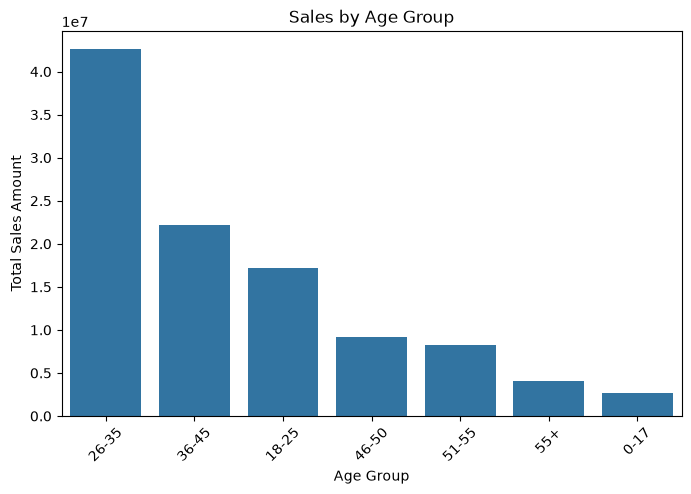

In [47]:
# Age group analysis
age_sales = df.groupby("Age Group")["Amount"].sum()
age_sales = age_sales.sort_values(ascending=False)
print(age_sales)

plt.figure(figsize=(8, 5))
sns.barplot(x=age_sales.index, y=age_sales.values)
plt.title("Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.show()

In [ ]:
Insight : I found that customers in the 26–35 age group contribute the most to total sales. 
This helps me understand age-group-wise purchasing patterns.

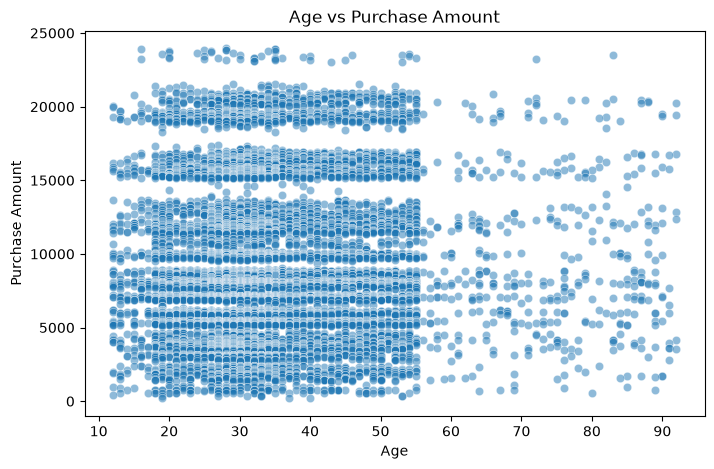

In [26]:
# Scatter Plot — Age vs Purchase Amount
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Age", y="Amount", alpha=0.5)

plt.title("Age vs Purchase Amount")
plt.xlabel("Age")
plt.ylabel("Purchase Amount")
plt.show()

In [ ]:
Insight: I found that purchase amounts vary across different age groups. The scatter plot helps me understand the relationship
between customer age and purchase amount and identify purchasing patterns.

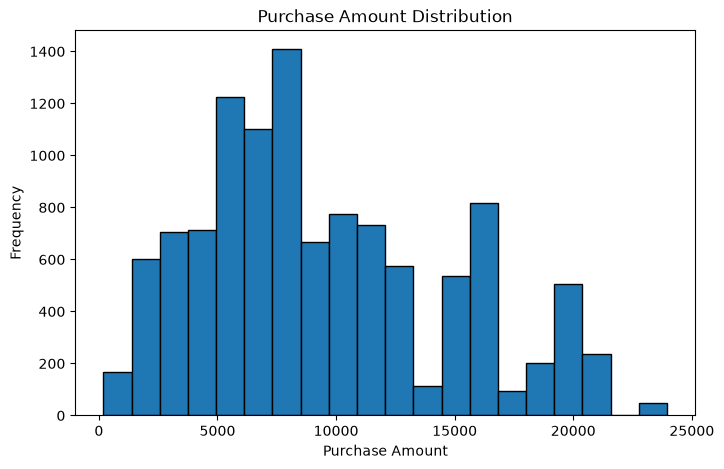

In [27]:
# Histogram — Purchase Amount Distribution
plt.figure(figsize=(8, 5))

plt.hist(df["Amount"], bins=20, edgecolor="black")
plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.show()

In [ ]:
Insight: I found that most purchase amounts are concentrated within certain value ranges. This histogram helps me understand the distribution 
of purchase amounts and identify the most frequent purchase ranges.

State
Uttar Pradesh       19346055.00
Maharashtra         14404467.00
Karnataka           13523540.00
Delhi               11603819.45
Madhya Pradesh       8101142.00
Andhra Pradesh       8037146.99
Himachal Pradesh     4963368.00
Haryana              4217871.00
Bihar                4014669.00
Gujarat              3938159.00
Name: Amount, dtype: float64


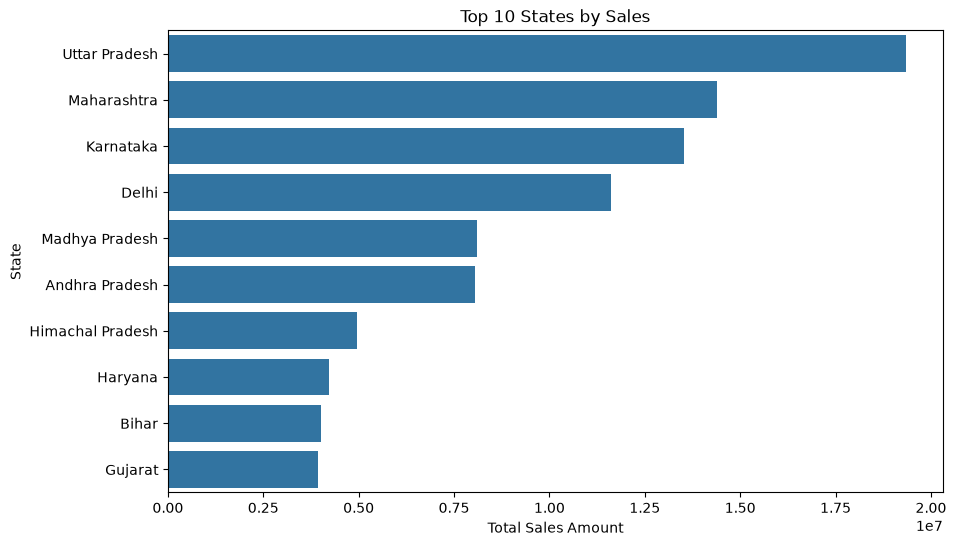

In [28]:
# State-wise sales analysis
state_sales = (
    df.groupby("State")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10))
print(state_sales)

plt.figure(figsize=(10, 6))
sns.barplot(x=state_sales.values, y=state_sales.index)
plt.title("Top 10 States by Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("State")
plt.show()

In [ ]:
Insight: I found that Uttar Pradesh state contribute more to total sales than other states.

Product_Category
Clothing & Apparel       6627
Food                     6110
Electronics & Gadgets    5208
Footwear & Shoes         2646
Household items          1331
Beauty                   1086
Games & Toys              940
Furniture                 889
Sports Products           870
Pet Care                  536
Stationery                281
Office                    261
Books                     245
Auto                      238
Decor                     235
Veterinary                206
Tupperware                166
Hand & Power Tools         80
Name: Orders, dtype: int64


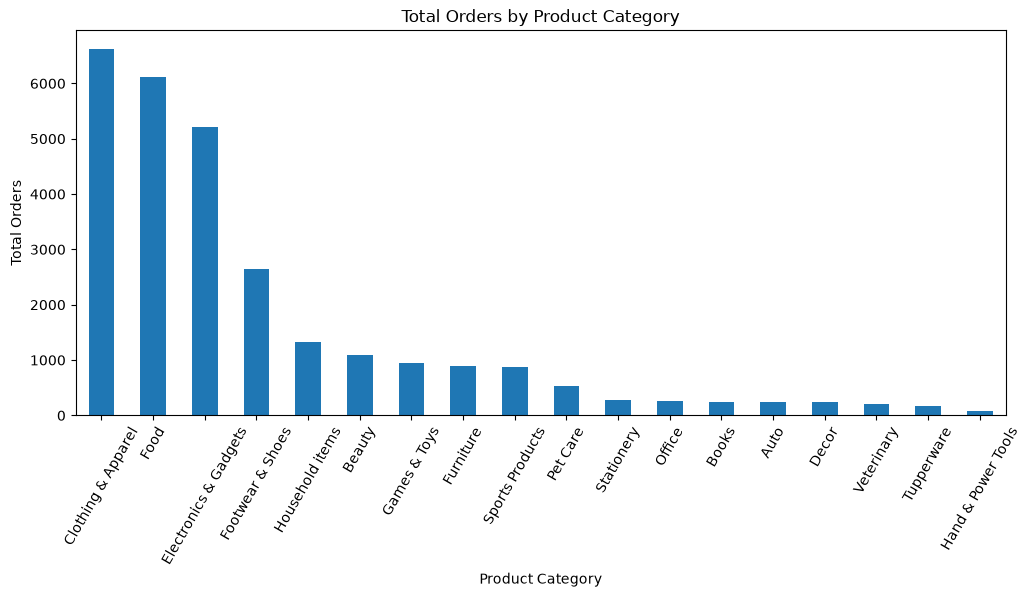

In [29]:
# Orders analysis
category_orders = (
    df.groupby("Product_Category")["Orders"]
    .sum()
    .sort_values(ascending=False))
print(category_orders)

category_orders.plot(kind="bar", figsize=(12, 5))
plt.title("Total Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Orders")
plt.xticks(rotation=60)
plt.show()

In [ ]:
Insight: I found that the Clothing and Apparel category has the highest number of orders, while Hand and 
Power Tools has the lowest number of orders.

Marital_Status            0            1
Gender                                  
F               43778560.44  30529121.99
M               18320176.00  13550970.00


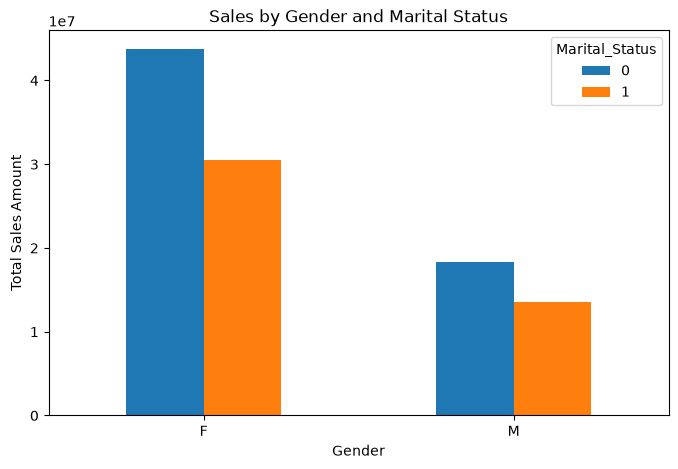

In [30]:
# Marital status &  gender analysis
gender_marital = df.pivot_table(
    index="Gender",
    columns="Marital_Status",
    values="Amount",
    aggfunc="sum")
print(gender_marital)

gender_marital.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by Gender and Marital Status")
plt.xlabel("Gender")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.show()

In [ ]:
Insight: I found that female customers contribute more to total sales than male customers across marital status categories. 

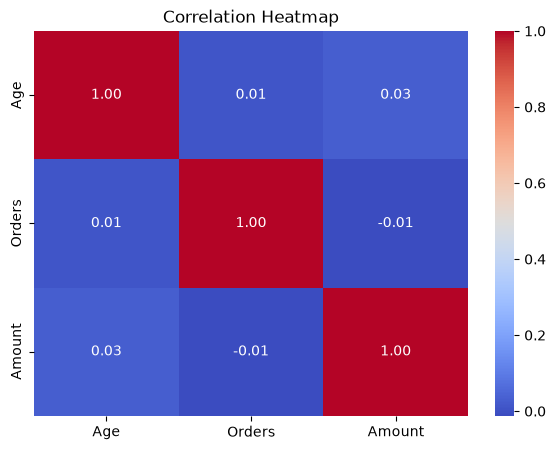

In [31]:
# Heatmap — Numerical Columns ka Correlation
corr_cols = ["Age", "Orders", "Amount"]
plt.figure(figsize=(7, 5))

sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

Insight: I found that Age and Amount have a very weak positive correlation of 0.03. Age and Orders also have a very weak positive correlation 
of 0.01, while Orders and Amount have a very weak negative correlation of -0.01. This indicates that there is almost no linear relationship between 
these numerical variables in my dataset.

In [ ]:
variance = df["Amount"].var()
print("variance",variance)

In [ ]:
list = [10,20,56,78,90]
print(list)

In [ ]:
list.append(100)
print(list)

In [ ]:
list.remove(56)
print(list)

In [ ]:
list.sort()
print(list)

In [ ]:
# MACHINE LEARNING FINAL PROJECT 

In [48]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Machine Learning models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [53]:
# Define Independent and Dependent Variables


# Define dependent variable
y = df['Amount']

# Define independent variables
X = df.drop(columns=[
    'Amount',
    'User_ID',
    'Cust_name',
    'Product_ID',
    'Status',
    'unnamed1'
], errors='ignore')

print("Independent Variables (X):", X.shape)
print("Dependent Variable (Y):", y.shape)

Independent Variables (X): (11231, 9)
Dependent Variable (Y): (11231,)


In [54]:
# Encode Categorical Variables

# Convert categorical columns into numerical format
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Categorical Encoding Completed!")
print("Updated X Shape:", X.shape)

display(X.head())

Categorical Encoding Completed!
Updated X Shape: (11231, 60)


,Age,Marital_Status,Orders,Gender_M,Age Group_18-25,Age Group_26-35,Age Group_36-45,Age Group_46-50,Age Group_51-55,Age Group_55+,...,Product_Category_Furniture,Product_Category_Games & Toys,Product_Category_Hand & Power Tools,Product_Category_Household items,Product_Category_Office,Product_Category_Pet Care,Product_Category_Sports Products,Product_Category_Stationery,Product_Category_Tupperware,Product_Category_Veterinary
0,28,0,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,35,1,3,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,35,1,3,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,16,0,2,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,28,1,2,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [55]:
# Split Data into Training and Testing  


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (8984, 60)
Testing Data: (2247, 60)
Training Target: (8984,)
Testing Target: (2247,)


In [56]:
#  Check Training Data

print("Training data missing values:")
print(X_train.isnull().sum().sum())

print("\nTesting data missing values:")
print(X_test.isnull().sum().sum())

Training data missing values:
0

Testing data missing values:
0


In [57]:
# Create Machine Learning Models

# Initialize Machine Learning Models

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    )
}

print("All Machine Learning Models Initialized Successfully!")

All Machine Learning Models Initialized Successfully!


In [58]:
# Train All Models

# Train all Machine Learning Models

for name, model in models.items():

    model.fit(X_train, y_train)

    print(name, "Training Completed Successfully!")

Linear Regression Training Completed Successfully!
Decision Tree Training Completed Successfully!
Random Forest Training Completed Successfully!
Gradient Boosting Training Completed Successfully!


In [59]:
# Make Predictions

# Store predictions of all models

predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(name, "Prediction Completed!")

Linear Regression Prediction Completed!
Decision Tree Prediction Completed!
Random Forest Prediction Completed!
Gradient Boosting Prediction Completed!


In [60]:
# Evaluate Model Performance

# Evaluate all Machine Learning Models

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print("Machine Learning Model Evaluation:")
display(results_df)

Machine Learning Model Evaluation:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2372.392524,9.902430e+06,3146.812615,0.638542
1,Decision Tree,3133.774335,1.944657e+07,4409.826463,0.290162
2,Random Forest,2446.537790,1.120229e+07,3346.982524,0.591094
3,Gradient Boosting,2483.520642,1.133307e+07,3366.462611,0.586320


In [61]:
# Compare Model Performance

# Compare models

results_df = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2372.392524,9.902430e+06,3146.812615,0.638542
2,Random Forest,2446.537790,1.120229e+07,3346.982524,0.591094
3,Gradient Boosting,2483.520642,1.133307e+07,3366.462611,0.586320
1,Decision Tree,3133.774335,1.944657e+07,4409.826463,0.290162


In [62]:
# Automatically select Best Model

# Select the best performing model

best_model_name = results_df.iloc[0]['Model']

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best R2 Score:", results_df.iloc[0]['R2 Score'])

Best Model: Linear Regression
Best R2 Score: 0.6385416716406673


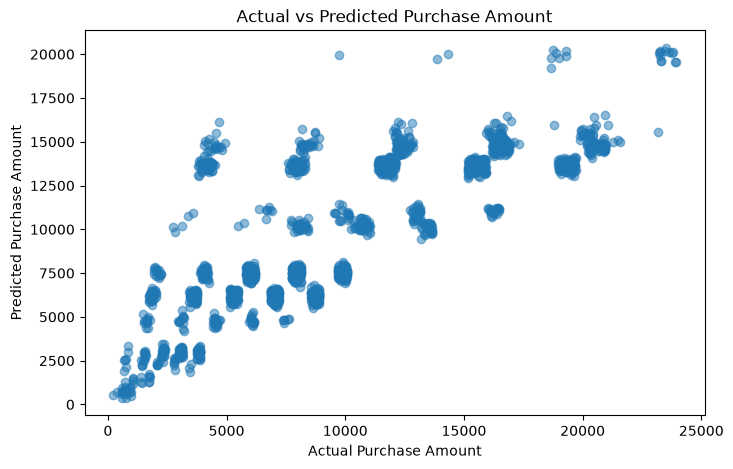

In [63]:
# Actual vs Predicted Visualization

# Actual vs Predicted Values

y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_best, alpha=0.5)

plt.xlabel("Actual Purchase Amount")
plt.ylabel("Predicted Purchase Amount")

plt.title("Actual vs Predicted Purchase Amount")

plt.show()

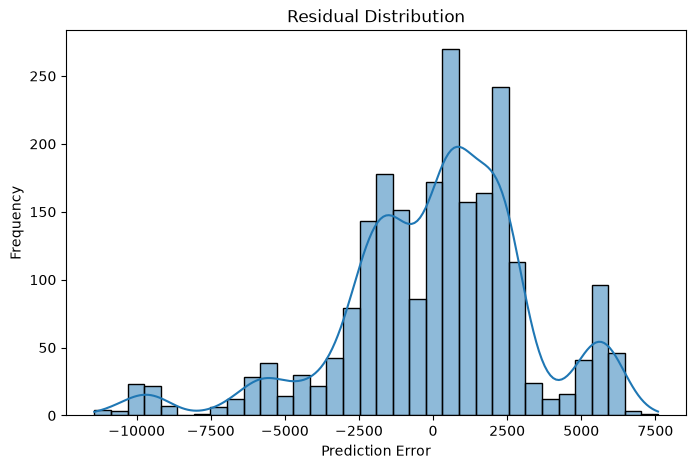

In [64]:
# Residual Analysis

# Calculate residuals

residuals = y_test - y_pred_best

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.title("Residual Distribution")

plt.show()

In [65]:
# Save Best Trained Model

import pickle
import os

# Save the best model and feature columns

model_artifact = {
    'model': best_model,
    'model_name': best_model_name,
    'feature_columns': X_train.columns.tolist()
}

with open('best_diwali_sales_model.pkl', 'wb') as file:
    pickle.dump(model_artifact, file)

print("Best Model Saved Successfully!")
print("File Location:", os.path.abspath('best_diwali_sales_model.pkl'))

Best Model Saved Successfully!
File Location: C:\Users\shiva\Desktop\best_diwali_sales_model.pkl


In [66]:
# Load Saved Model and Make Prediction

# Load saved model

with open('best_diwali_sales_model.pkl', 'rb') as file:
    loaded_artifact = pickle.load(file)

loaded_model = loaded_artifact['model']

print("Model Loaded Successfully!")
print("Model Name:", loaded_artifact['model_name'])

Model Loaded Successfully!
Model Name: Linear Regression


In [67]:
#  test customer prediction 

# Select one test customer

new_customer = X_test.iloc[[0]]

# Predict purchase amount

predicted_amount = loaded_model.predict(new_customer)

print("Predicted Purchase Amount:", predicted_amount[0])

print("Actual Purchase Amount:", y_test.iloc[0])

Predicted Purchase Amount: 2863.1155327360793
Actual Purchase Amount: 3016.0


In [68]:
import os

print(os.getcwd())

C:\Users\shiva\Desktop
